# 11 - K-Means Clustering

Part of the **Data Science Learning** project. Explanations, comments, and notebook messages are in English.

## Learning objectives
Explore unsupervised clustering and the elbow method.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_diabetes, make_blobs
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

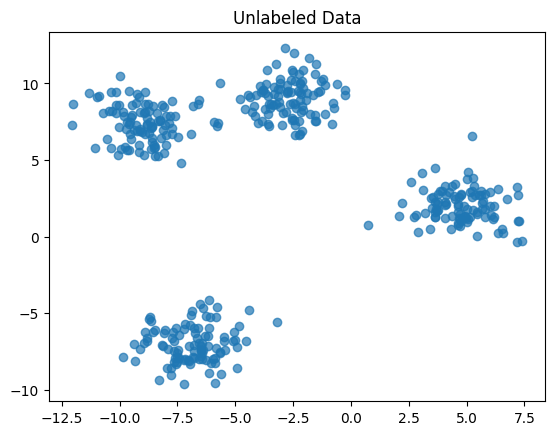

In [2]:
from sklearn.cluster import KMeans

X_array, _ = make_blobs(n_samples=400, centers=4, cluster_std=1.2, random_state=RANDOM_STATE)
X = pd.DataFrame(X_array, columns=["feature_1", "feature_2"])
plt.scatter(X["feature_1"], X["feature_2"], alpha=0.7)
plt.title("Unlabeled Data")
plt.show()

## Use the elbow method

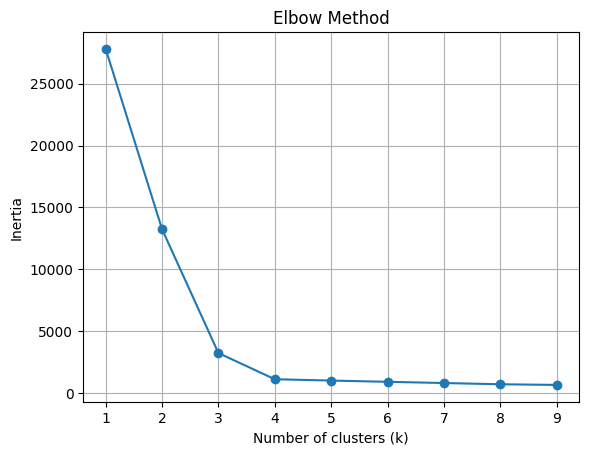

In [3]:
inertias = []
k_values = range(1, 10)
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X)
    inertias.append(model.inertia_)

plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

## Fit K-Means

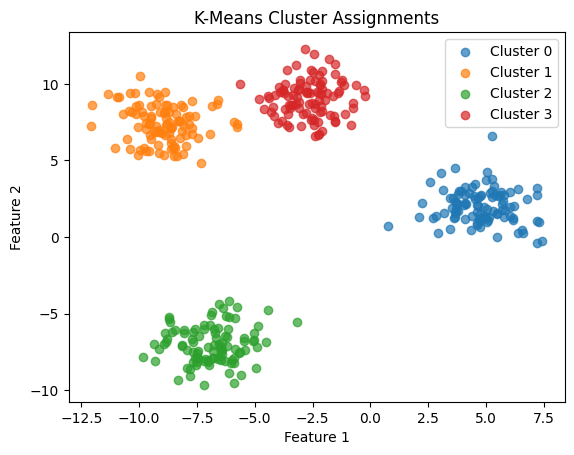

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
model = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
X["cluster"] = model.fit_predict(X_scaled)

for cluster_id in sorted(X["cluster"].unique()):
    subset = X[X["cluster"] == cluster_id]
    plt.scatter(subset["feature_1"], subset["feature_2"], label=f"Cluster {cluster_id}", alpha=0.7)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Cluster Assignments")
plt.legend()
plt.show()

## Exercises
1. Try 3 and 5 clusters.
2. Change the synthetic dataset's cluster spread.
3. Explain why cluster labels are not rankings.